# Simulación dosimétrica comparativa: vial de F-18 FDG con blindaje de plomo y tungsteno

## Tabla de contenidos

1. [Geometría del sistema](#1-geometría-del-sistema)
   - Capas radiales y axiales
   - Vial de vidrio y fuente
   - Detectores grupo A y B

2. [Materiales, detectores y fuente](#2-materiales-detectores-y-fuente)
   - Materiales personalizados
   - Configuración de la fuente

3. [Análisis de resultados](#3-análisis-de-resultados)
   - Lectura de datos
   - Consideraciones metodológicas
   - 3.1 Mapas de calor
   - 3.2 Validación estadística
   - 3.3 Dosis por detector
   - 3.4 Atenuación a través del blindaje
     - Perfil de dosis vs posición
     - Transmitancia

Este trabajo analiza el comportamiento de la tasa de dosis emitida por una disolución acuosa de F-18 FDG de 100 mCi, realizando mediciones de la tasa de dosis a diferentes distancias del vial, esto para dos contenedores blindados: el CT/A-30 (plomo + acero inoxidable) y el CT/A-30W (tungsteno). La simulación se realizó con GATE 10, que permite seguir el transporte de cada partícula a través de la geometría y registrar la energía depositada en detectores de tejido blando.

Este notebook no contiene la simulación — eso lo hacen los scripts `vial_plomo_v3.py` y `vial_tungsteno_v3.py`. Acá se leen los resultados generados por GATE (archivos `.mhd/.raw` y `metadata_simulacion.json`) y se calculan las magnitudes de interés: distribución espacial de dosis, incertidumbre estadística, dosis equivalente en sieverts, perfil de atenuación a través del blindaje y transmitancia por detector.

## 1. Geometría del sistema

Se simularon dos contenedores blindados para el mismo radiofármaco. El CT/A-30 usa plomo como blindaje principal con una carcasa exterior de acero inoxidable. El CT/A-30W usa tungsteno. Las dimensiones de cada uno se obtuvieron de la ficha técnica del fabricante.

**Tabla 1 — Capas radiales** (medidas desde el eje central del cilindro)

| Capa | Radio int. | Radio ext. | Espesor | Radio int. | Radio ext. | Espesor |
|---|---|---|---|---|---|---|
| | **CT/A-30 (plomo)** | | | **CT/A-30W (tungsteno)** | | |
| Cavidad de aire | 0 mm | 16.5 mm | 16.5 mm | 0 mm | 16.75 mm | 16.75 mm |
| Blindaje principal | 16.5 mm | 48.5 mm | **32.0 mm (Pb)** | 16.75 mm | 46.25 mm | **29.5 mm (W)** |
| Carcasa de acero | 48.5 mm | 50.5 mm | 2.0 mm | — | — | — |

**Tabla 2 — Capas axiales** (medidas desde el centro del contenedor hacia cada tapa)

| Capa | Desde | Hasta | Espesor | Desde | Hasta | Espesor |
|---|---|---|---|---|---|---|
| | **CT/A-30 (plomo)** | | | **CT/A-30W (tungsteno)** | | |
| Cavidad de aire | 0 mm | 37.0 mm | 37.0 mm | 0 mm | 28.5 mm | 28.5 mm |
| Blindaje principal (tapa) | 37.0 mm | 55.75 mm | **18.75 mm (Pb)** | 28.5 mm | 50.25 mm | **21.75 mm (W)** |
| Carcasa de acero (tapa) | 55.75 mm | 57.75 mm | 2.0 mm | — | — | — |

**Tabla 3 — Vial de vidrio y fuente de agua** (igual en ambos contenedores)

| Elemento | Radio | Altura/espesor | Posición (centro en Z) |
|---|---|---|---|
| Pared del vial | 11.0 – 12.5 mm | 45.0 mm | z = −13.0 mm (plomo) / z = −4.5 mm (tungsteno) |
| Fondo del vial | 0 – 11.0 mm | 1.5 mm | z = −36.25 mm (plomo) / z = −27.75 mm (tungsteno) |
| Agua (10 mL, F-18 FDG) | 0 – 11.0 mm | 26.3 mm | z = −22.35 mm (plomo) / z = −13.85 mm (tungsteno) |

Algunas dimensiones presentan ligeras variaciones respecto a la ficha técnica, del orden de pocos milímetros, introducidas para evitar solapamientos geométricos en la simulación.

## 2. Materiales, detectores y fuente

Las librerías de GATE no incluyen todos los materiales necesarios, por lo que permite definirlos a partir de su composición atómica y densidad. En este proyecto se definieron manualmente el acero inoxidable, el plomo y el tungsteno. El resto de materiales (`G4_WATER`, `G4_AIR`, `G4_Pyrex_Glass`, `G4_TISSUE_SOFT_ICRP`) ya están predefinidos en Geant4 y no requieren definición adicional.

### Materiales utilizados en la simulación

**Tabla — Materiales personalizados** (definidos con `add_material_nb_atoms`, proporción por número de átomos)

| Material | Composición | Densidad | Contenedor | Dónde se usa |
|---|---|---|---|---|
| `StainlessSteel` | Fe : Cr : Ni = 70 : 20 : 10 | 7.81 g/cm³ | Plomo | Carcasa exterior |
| `Lead` | Pb (puro) | 11.4 g/cm³ | Plomo | Blindaje principal |
| `Tungsten` | W (puro) | 19.3 g/cm³ | Tungsteno | Blindaje principal |



### Detectores — secciones de esfera

Para medir la tasa de dosis a diferentes distancias del contenedor se definieron cinco secciones de esfera de agua (`G4_WATER`) centradas en el origen del sistema. Cada sección cubre un ángulo theta de 0° a 90° (semiesfera superior en Z) y un ángulo phi de 150° a 210° (±30° desde X negativo), con 1 mm de espesor.

**Tabla 4 — Secciones de esfera (igual en ambos contenedores)**

| Detector | Radio (mm) | Distancia desde superficie (mm) | Theta | Phi | Material |
|---|---|---|---|---|---|
| `esfera_250.5mm` | 250.5 | 200 (20 cm) | 0°–90° | 150°–210° | G4_WATER |
| `esfera_450.5mm` | 450.5 | 400 (40 cm) | 0°–90° | 150°–210° | G4_WATER |
| `esfera_650.5mm` | 650.5 | 600 (60 cm) | 0°–90° | 150°–210° | G4_WATER |
| `esfera_850.5mm` | 850.5 | 800 (80 cm) | 0°–90° | 150°–210° | G4_WATER |
| `esfera_1050.5mm` | 1050.5 | 1000 (100 cm) | 0°–90° | 150°–210° | G4_WATER |

Para el contenedor de tungsteno los radios difieren levemente (246.25, 446.25, 646.25, 846.25, 1046.25 mm) porque la superficie externa es de 46.25 mm en vez de 50.5 mm, manteniendo la misma distancia desde la superficie en ambos casos.

La fuente radiactiva modelada es **F-18** (Flúor-18), en forma de FDG (fluorodesoxiglucosa),
disuelta uniformemente en los 10 mL de agua contenidos en el vial.

**Tabla 6 — Configuración de la fuente en la simulación**

| Parámetro | Valor |
|---|---|
| Partícula simulada | Ion (Z=9, A=18) — decaimiento gestionado por Geant4 (`enable_decay = True`) |
| Modo de decaimiento principal | Emisión β⁺ |
| Distribución espacial | Uniforme dentro del volumen de agua (`waterCil`) |
| Tipo de posición | Cilindro: radio 11.0mm, semi-altura 13.15mm |
| Distribución angular | Isotrópica (`iso`) |
| Physics list | `QGSP_BIC_EMZ` |


**Datos nucleares usados en el cálculo** (fuente: LNHB/CEA), necesarios para la
energía media emitida por decaimiento que usa la simulación:

| Parámetro | Valor | Uso en el código |
|---|---|---|
| Rama β⁺ | 96.86% | Fracción de decaimientos que emiten positrón |
| Energía media del positrón | 249.5 keV | Aporta a la energía media por decaimiento |
| Fotones de aniquilación por decaimiento | 1.9372 (× 511 keV) | Aporta a la energía media por decaimiento |

$$E_{media} = 0.9686 \times 0.2495\ \text{MeV} + 1.9372 \times 0.511\ \text{MeV} = 1.2312\ \text{MeV/decaimiento}$$



## 3. Análisis de resultados

Los resultados se analizan en tres etapas: validación estadística de cada esfera, cuantificación de la tasa de dosis en Sv/h a cada distancia, y comparación con el modelo teórico analítico.

### Lectura de datos

Se definen las rutas donde GATE almacenó los resultados y se cargan los metadatos de la simulación.

In [11]:
import json
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
# --- Parámetros nucleares del F-18 ---
T_HALF_MIN = 109.77          # Semivida del F-18 en minutos
LAMBDA = np.log(2) / (T_HALF_MIN * 60)  # Constante de desintegración en s^-1

# --- Los dos contenedores a comparar ---
CONTENEDORES = {
    "Plomo (CT/A-30)":      "resultados/plomo/plano_{d}mm",
    "Tungsteno (CT/A-30W)": "resultados/tungsteno/plano_{d}mm",
}


TIEMPO_EXPOSICION_S = 3600.0  # 1 hora de exposición
A_0_MCI = 100.0                # Actividad inicial en mCi
BQ_POR_MCI = 3.7e7

# --- Corrección por decaimiento radiactivo en 1 hora ---
# Actividad media integrada durante el tiempo de exposición: A_mean = A_0 * (1 - e^(-lambda * t)) / (lambda * t)
factor_decaimiento = (1 - np.exp(-LAMBDA * TIEMPO_EXPOSICION_S)) / (LAMBDA * TIEMPO_EXPOSICION_S)
actividad_efectiva_mci = A_0_MCI * factor_decaimiento

print(f"Actividad inicial: {A_0_MCI} mCi")
print(f"Actividad media efectiva en 1 hora: {actividad_efectiva_mci:.2f} mCi")

W_R = 1.0       # Gy -> Sv, 1.0 para fotones/electrones

def leer_mhd(ruta_mhd: Path):
    """Lee un par .mhd/.raw generado por GATE y devuelve (array numpy, spacing_mm)."""
    header = {}
    with open(ruta_mhd, "r") as f:
        for linea in f:
            if "=" in linea:
                clave, valor = linea.split("=", 1)
                header[clave.strip()] = valor.strip()
    print(f"DimSize raw: '{header.get('DimSize')}'")
    dim_size = [int(x) for x in header["DimSize"].split()]
    print(f"dim_size parsed: {dim_size}")
    spacing_key = "ElementSpacing" if "ElementSpacing" in header else "ElementSize"
    spacing_mm = [float(x) for x in header[spacing_key].split()]

    tipos = {"MET_FLOAT": np.float32, "MET_DOUBLE": np.float64}
    dtype = tipos.get(header.get("ElementType", "MET_FLOAT"), np.float32)

    ruta_raw = ruta_mhd.parent / header["ElementDataFile"]
    datos = np.fromfile(ruta_raw, dtype=dtype)
    return datos.reshape(dim_size[::-1]), spacing_mm  # (Z, Y, X)


def buscar_archivo(carpeta, nombre_volumen, sufijo="dose"):
    """Busca el archivo .mhd de dosis para un volumen dado."""
    patron = f"*{nombre_volumen}*-{sufijo}.mhd"
    resultados = list(Path(carpeta).glob(patron))
    if resultados:
        return resultados[0]
    return None



def incertidumbre_combinada(dose_arr, uncert_arr):
    """
    Calcula la incertidumbre relativa combinada de un DoseActor.
    uncert_arr contiene la incertidumbre relativa vóxel a vóxel.
    Retorna la incertidumbre relativa promedio ponderada por dosis.
    """
    mask = dose_arr > 0
    if not np.any(mask):
        return 0.0
    pesos = dose_arr[mask]
    return float(np.average(uncert_arr[mask], weights=pesos))

Actividad inicial: 100.0 mCi
Actividad media efectiva en 1 hora: 83.24 mCi


Se definen los parámetros de la simulación, las rutas de resultados y las funciones de lectura. Los archivos `.mhd/.raw` generados por GATE requieren lectura binaria antes de poder analizarlos.

### Consideraciones metodológicas

El número real de decaimientos en 1 hora a 10 mCi es:

$$N_{real} = 10\ \text{mCi} \times 3.7 \times 10^7\ \text{Bq/mCi} \times 3600\ \text{s} = 1.33 \times 10^{12}\ \text{decaimientos}$$

Simular ese número es computacionalmente inviable. Por eso se simula una fracción representativa y se aplica un **factor de escala** que magnifica los resultados proporcionalmente:

$$\text{factor} = \frac{A \times t}{N_{primarios}} $$

Este factor escala la amplitud de los resultados pero no su forma espacial ni las relaciones relativas entre detectores.

Como la simulación es estadística, pocos primarios producen resultados ruidosos aunque el factor de escala sea correcto. Por eso se evalúa la **incertidumbre relativa** de cada detector. Se tomará como aceptable resultados con incertidumbre menor al 10%.

### 3.1 Validación estadística

Se evalúa la incertidumbre relativa de cada esfera antes de interpretar los valores de dosis. El criterio de aceptación es incertidumbre menor al 10%. Se espera que las esferas más lejanas (80 y 100 cm) presenten mayor incertidumbre por recibir menos impactos tras atravesar el blindaje completo.

$$\sigma_{rel} = \frac{\sqrt{\sum_i (\sigma_i \cdot D_i)^2}}{\sum_i D_i}$$

**Lectura de los mapas de calor:** `det_palma` y `det_dedos` muestran distribuciones densas porque están en contacto directo con el contenedor y reciben muchos impactos. En cambio, `det_torso`, `det_cabeza` y `det_manos` (a 15 cm de la superficie, tras atravesar el blindaje completo) muestran mapas más apagados. 

### 3.1 Validación estadística

Como se mencionó antes, se tomarán como válidos resultados con incertidumbre relativa menor al 10%. Valores por encima indican que se necesitan más primarios simulados para que el resultado sea confiable.

La incertidumbre relativa combinada de un detector se calcula propagando la incertidumbre absoluta de cada vóxel y normalizando por la dosis total del detector:

$$\sigma_{rel} = \frac{\sqrt{\sum_i (\sigma_i \cdot D_i)^2}}{\sum_i D_i}$$

donde $D_i$ es la dosis en el vóxel $i$ y $\sigma_i$ es su incertidumbre relativa reportada por GATE. El numerador acumula la incertidumbre absoluta de cada vóxel en cuadratura (asumiendo independencia estadística entre vóxeles), y el denominador normaliza por la dosis total del detector para obtener una incertidumbre relativa global comparable entre detectores de distinto tamaño.

In [12]:
import json, zlib
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.lines import Line2D

# Carpetas de resultados (una por contenedor y distancia)
BASE        = Path(".")                       # raíz del repo (donde está la carpeta resultados/)
RES_DIR = BASE / "resultados"; FIG_DIR = RES_DIR / "figuras"; FIG_DIR.mkdir(parents=True, exist_ok=True)
DISTANCIAS  = [200, 400, 600, 800, 1000]      # mm desde el eje del contenedor
CONTENEDORES = {
    "Plomo (CT/A-30)":      "resultados/plomo/plano_{d}mm",
    "Tungsteno (CT/A-30W)": "resultados/tungsteno/plano_{d}mm",
    "Sin blindaje": "resultados/sin_blindaje/plano_{d}mm_t5mm",
}
COLORES = {"Plomo (CT/A-30)": "#2a78d6", "Tungsteno (CT/A-30W)": "#eb6834",
           "Sin blindaje": "#8a8a85"}
REF = "Sin blindaje"
# Escenario de exposición
ACTIVIDAD_MCI        = 100.0
T_EXPO_S             = 3600.0                  # 1 h
T_MEDIA_F18_S        = 109.77 * 60
CORREGIR_DECAIMIENTO = True                    # False = actividad constante
BQ_POR_MCI           = 3.7e7
UMBRAL_INCERT        = 0.10                    # criterio de aceptación (10 %)

# Referencia "sin blindaje" (fuente puntual en vacío)
FOTONES_POR_DECAIM = 1.9372                    # fotones de 511 keV por decaimiento de F-18
E_FOTON_MEV        = 0.511
MUEN_RHO_CM2_G     = 0.0330                    # μen/ρ tejido blando @ 511 keV (NIST, ≈ agua)
MEV_A_J            = 1.602176634e-13

# Estilo de gráficos: líneas finas, rejilla tenue, sin marco superior/derecho
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "grid.linewidth": 0.6,
    "axes.titlesize": 11, "axes.labelsize": 10, "legend.frameon": False,
    "font.size": 10,
})
TINTA = "#0b0b0b"; TINTA2 = "#52514e"
CMAP_AZUL = LinearSegmentedColormap.from_list("azul", ["#cde2fb", "#86b6ef", "#2a78d6", "#184f95", "#0d366b"])

# ── Lector de .mhd (sin dependencias; devuelve array (nz, ny, nx)) ──
_TIPOS = {"MET_FLOAT": "f4", "MET_DOUBLE": "f8", "MET_UCHAR": "u1",
          "MET_SHORT": "i2", "MET_USHORT": "u2", "MET_INT": "i4", "MET_UINT": "u4"}

def leer_mhd(ruta):
    ruta = Path(ruta); h = {}
    for linea in ruta.read_text().splitlines():
        if "=" in linea:
            k, v = linea.split("=", 1); h[k.strip()] = v.strip()
    dims = [int(x) for x in h["DimSize"].split()]
    msb  = h.get("BinaryDataByteOrderMSB", h.get("ElementByteOrderMSB", "False")).lower() == "true"
    dt   = np.dtype(_TIPOS[h["ElementType"]]).newbyteorder(">" if msb else "<")
    raw  = (ruta.parent / h["ElementDataFile"]).read_bytes()
    if h.get("CompressedData", "False").lower() == "true":
        raw = zlib.decompress(raw)
    return np.frombuffer(raw, dtype=dt).reshape(dims[::-1]).astype(float)

def buscar_archivos(carpeta, d):
    """Devuelve (mhd_dosis, mhd_incertidumbre). Compara solo el sufijo tras 'dose_det_<d>mm'
    para no confundir '...-Edep.mhd' con dosis (el prefijo ya contiene 'dose')."""
    stem = f"dose_det_{d}mm".lower(); dosis = unc = None
    for f in sorted(Path(carpeta).glob("*.mhd")):
        suf = f.name.lower().replace(stem, "")
        if "uncert" in suf and ("dose" in suf or unc is None):
            unc = f
        elif "dose" in suf and "squared" not in suf and "uncert" not in suf:
            dosis = f
    return dosis, unc

In [13]:
datos = {}
for cont, patron in CONTENEDORES.items():
    datos[cont] = {}
    for d in DISTANCIAS:
        carpeta = BASE / patron.format(d=d)
        if not carpeta.exists():
            print(f"[FALTA] {cont} · {d} mm → no existe {carpeta}"); continue
        f_dosis, f_unc = buscar_archivos(carpeta, d)
        f_meta = carpeta / "metadata_simulacion.json"
        if f_dosis is None or f_unc is None or not f_meta.exists():
            print(f"[INCOMPLETO] {carpeta}: dosis={f_dosis} unc={f_unc} meta={f_meta.exists()}"); continue
        meta = json.loads(f_meta.read_text(encoding="utf-8"))
        datos[cont][d] = dict(
            dosis  = leer_mhd(f_dosis)[:, :, 0],   # (nz, ny)  dosis TOTAL de la corrida (Gy)
            unc    = leer_mhd(f_unc)[:, :, 0],     # incertidumbre relativa por vóxel
            n_prim = meta["n_primarios_simulados"],
            lado   = meta["detector"]["lado_mm"],
        )
        print(f"[OK] {cont:22s} {d:5d} mm | {datos[cont][d]['n_prim']:>12,} primarios | "
              f"{f_dosis.name}, {f_unc.name}")

[FALTA] Plomo (CT/A-30) · 200 mm → no existe resultados/plomo/plano_200mm
[FALTA] Plomo (CT/A-30) · 400 mm → no existe resultados/plomo/plano_400mm
[FALTA] Plomo (CT/A-30) · 600 mm → no existe resultados/plomo/plano_600mm
[FALTA] Plomo (CT/A-30) · 800 mm → no existe resultados/plomo/plano_800mm
[FALTA] Plomo (CT/A-30) · 1000 mm → no existe resultados/plomo/plano_1000mm
[FALTA] Tungsteno (CT/A-30W) · 200 mm → no existe resultados/tungsteno/plano_200mm
[FALTA] Tungsteno (CT/A-30W) · 400 mm → no existe resultados/tungsteno/plano_400mm
[FALTA] Tungsteno (CT/A-30W) · 600 mm → no existe resultados/tungsteno/plano_600mm
[FALTA] Tungsteno (CT/A-30W) · 800 mm → no existe resultados/tungsteno/plano_800mm
[FALTA] Tungsteno (CT/A-30W) · 1000 mm → no existe resultados/tungsteno/plano_1000mm
[OK] Sin blindaje             200 mm |    5,000,000 primarios | dose_det_200mm_dose.mhd, dose_det_200mm_dose_uncertainty.mhd
[OK] Sin blindaje             400 mm |    5,000,000 primarios | dose_det_400mm_dose.mh

In [14]:
LAMBDA = np.log(2) / T_MEDIA_F18_S
A0_BQ  = ACTIVIDAD_MCI * BQ_POR_MCI
N_DEC  = (A0_BQ / LAMBDA) * (1 - np.exp(-LAMBDA * T_EXPO_S)) if CORREGIR_DECAIMIENTO \
         else A0_BQ * T_EXPO_S
print(f"Decaimientos reales en {T_EXPO_S/60:.0f} min: {N_DEC:.4e} "
      f"({'con' if CORREGIR_DECAIMIENTO else 'sin'} corrección por decaimiento)")

filas = []
for cont, por_d in datos.items():
    for d, r in sorted(por_d.items()):
        f = N_DEC / r["n_prim"]                       # decaimientos reales / primarios simulados
        D = r["dosis"] * f                            # Gy en cada vóxel
        u = np.where(r["dosis"] > 0, r["unc"], 1.0)   # vóxel sin eventos → 100 %
        media = D.mean()                              # Gy es intensiva → media sobre vóxeles
        sigma_media = np.sqrt(np.sum((D * u) ** 2)) / D.size   # incertidumbre estadística de la media
        c = D.shape[0] // 2
        r.update(D=D, u=u, factor=f, media=media, sigma_media=sigma_media)
        filas.append({
            "Contenedor": cont, "d (mm)": d, "Primarios": r["n_prim"],
            "Media plano (µGy)":       media * 1e6,
            "σ estadística (%)":       100 * sigma_media / media,
            "Desv. espacial (µGy)":    D.std(ddof=1) * 1e6,    # variación entre vóxeles
            "CV espacial (%)":         100 * D.std(ddof=1) / media,
            "Centro (µGy)":            D[c, c] * 1e6,
            "Incert. centro (%)":      100 * u[c, c],
            "Incert. máx vóxel (%)":   100 * u.max(),
            "¿< 10 % en todos?":       "sí" if u.max() <= UMBRAL_INCERT else "NO",
        })
tabla = pd.DataFrame(filas)
display(tabla.round({"Media plano (µGy)": 4, "σ estadística (%)": 2, "Desv. espacial (µGy)": 4,
                     "CV espacial (%)": 1, "Centro (µGy)": 4, "Incert. centro (%)": 2,
                     "Incert. máx vóxel (%)": 1}))

Decaimientos reales en 60 min: 1.1087e+13 (con corrección por decaimiento)


,Contenedor,d (mm),Primarios,Media plano (µGy),σ estadística (%),Desv. espacial (µGy),CV espacial (%),Centro (µGy),Incert. centro (%),Incert. máx vóxel (%),¿< 10 % en todos?
0,Sin blindaje,200,5000000,8535.6613,0.70,686.9830,8.0,9977.0217,1.95,2.2,sí
1,Sin blindaje,400,5000000,2138.2042,0.70,143.4160,6.7,2377.4760,1.99,2.2,sí
2,Sin blindaje,600,5000000,998.8025,0.68,74.8189,7.5,1148.5314,1.91,2.1,sí
3,Sin blindaje,800,5000000,527.3703,0.70,41.2912,7.8,594.2609,1.99,2.2,sí
4,Sin blindaje,1000,5000000,307.4304,0.74,25.8843,8.4,359.5715,2.05,2.3,sí


Sin blindaje            exponente n = 2.038 ± 0.006   (1/r² → n = 2)


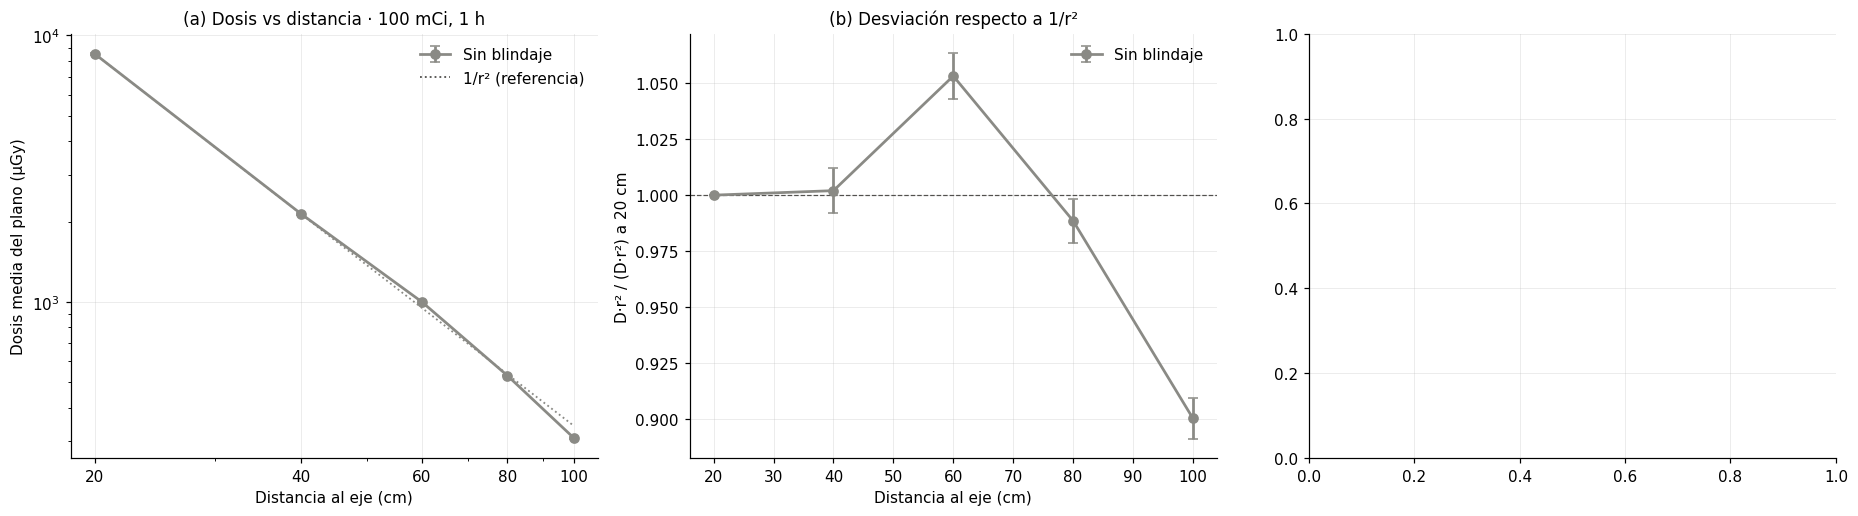

In [15]:
from matplotlib.ticker import NullFormatter

def serie(cont):
    ds = sorted(datos[cont]); r = [datos[cont][d] for d in ds]
    x   = np.array(ds) / 10.0                                  # cm
    m   = np.array([k["media"] for k in r]) * 1e6              # µGy
    rel = np.array([k["sigma_media"] / k["media"] for k in r])
    return x, m, rel

fig, ax = plt.subplots(1, 3, figsize=(17, 4.8))
S = {}
for cont in CONTENEDORES:
    if not datos[cont]: continue
    x, m, rel = serie(cont); S[cont] = (x, m, rel); c = COLORES[cont]
    # (a) dosis media vs distancia (log-log) + referencia 1/r² anclada al primer punto
    ax[0].errorbar(x, m, yerr=m * rel, fmt="o-", color=c, ms=6, lw=1.8, capsize=3, label=cont)
    ax[0].plot(x, m[0] * (x[0] / x) ** 2, ls=":", color=c, lw=1.2)
    # ajuste D ∝ r^-n ponderado por la incertidumbre
    p, cov = np.polyfit(np.log(x), np.log(m), 1, w=1 / np.maximum(rel, 1e-6), cov="unscaled")
    print(f"{cont:22s}  exponente n = {-p[0]:.3f} ± {np.sqrt(cov[0, 0]):.3f}   (1/r² → n = 2)")
    # (b) D·r² normalizado al primer punto (si solo fuera geometría → 1)
    y = m * x ** 2; y = y / y[0]
    ey = y * np.sqrt(rel ** 2 + rel[0] ** 2); ey[0] = 0
    ax[1].errorbar(x, y, yerr=ey, fmt="o-", color=c, ms=6, lw=1.8, capsize=3, label=cont)

ax[0].set(xscale="log", yscale="log", xlabel="Distancia al eje (cm)", ylabel="Dosis media del plano (µGy)",
          title="(a) Dosis vs distancia · 100 mCi, 1 h")
ax[0].set_xticks([d / 10 for d in DISTANCIAS]); ax[0].set_xticklabels([f"{d/10:.0f}" for d in DISTANCIAS])
ax[0].xaxis.set_minor_formatter(NullFormatter())
h = ax[0].get_legend_handles_labels()
ax[0].legend(h[0] + [Line2D([], [], ls=":", color=TINTA2, lw=1.2)], h[1] + ["1/r² (referencia)"])
ax[1].axhline(1, color=TINTA2, lw=0.8, ls="--")
ax[1].set(xlabel="Distancia al eje (cm)", ylabel="D·r² / (D·r²) a 20 cm",
          title="(b) Desviación respecto a 1/r²"); ax[1].legend()

# (c) cuántas veces atenúa más el tungsteno que el plomo
pb, w = list(CONTENEDORES)[:2]
if pb in S and w in S:
    x, m1, r1 = S[pb]; _, m2, r2 = S[w]
    ratio = m1 / m2; err = ratio * np.sqrt(r1 ** 2 + r2 ** 2)
    ax[2].errorbar(x, ratio, yerr=err, fmt="o-", color=TINTA2, ms=6, lw=1.8, capsize=3)
    ax[2].set(xlabel="Distancia al eje (cm)", ylabel="Dosis Pb / Dosis W",
              title="(c) Atenuación extra del tungsteno", ylim=(0, (ratio + err).max() * 1.25))
    for xi, ri in zip(x, ratio): ax[2].annotate(f"{ri:.1f}×", (xi, ri), textcoords="offset points",
                                                xytext=(0, 9), ha="center", fontsize=9, color=TINTA)
fig.tight_layout(); fig.savefig(FIG_DIR / "fig_atenuacion.png", dpi=200, bbox_inches="tight"); plt.show()

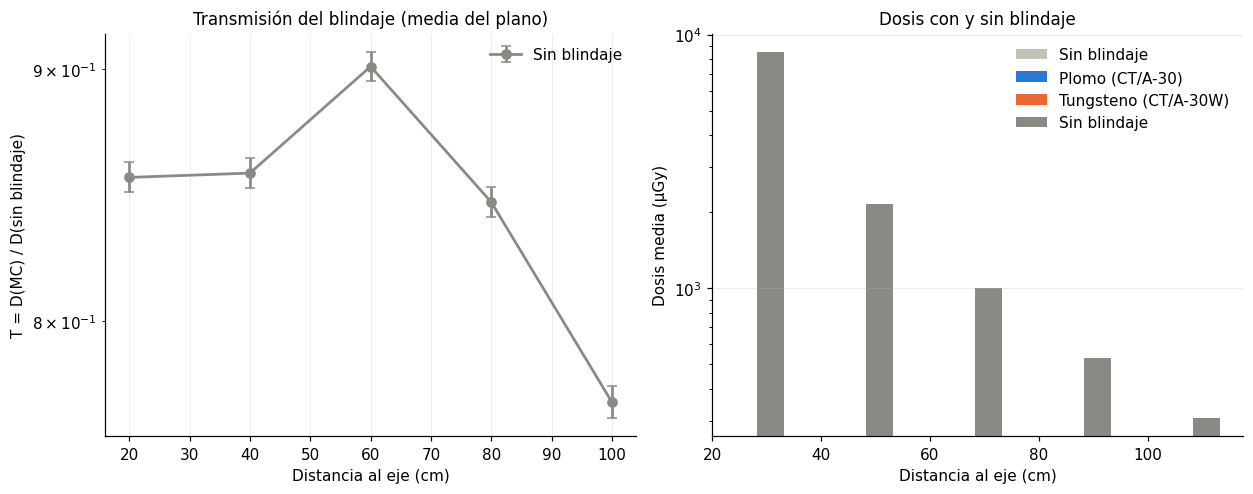

,Contenedor,d (mm),Sin blindaje (µGy),Con blindaje MC (µGy),Transmisión T,± T,Atenuación 1/T,T centro
0,Sin blindaje,200,9975.581,8535.6613,0.85566,0.00598,1.2,0.87995
1,Sin blindaje,400,2493.895,2138.2042,0.85738,0.00598,1.2,0.83875
2,Sin blindaje,600,1108.398,998.8025,0.90112,0.00614,1.1,0.91168
3,Sin blindaje,800,623.474,527.3703,0.84586,0.00595,1.2,0.83860
4,Sin blindaje,1000,399.023,307.4304,0.77046,0.00567,1.3,0.79284


In [16]:
def dosis_sin_blindaje(d_mm, lado_mm, nvox, n_dec, sub=10):
    """Dosis (Gy) en cada vóxel si NO hubiera contenedor: D = Φ·E·(μen/ρ), Φ = N·1.9372/(4π r²).
    Se promedia 1/r² dentro de cada vóxel (sub×sub puntos). Devuelve array (nz, ny)."""
    c = (np.arange(nvox * sub) + 0.5) / (nvox * sub) * lado_mm - lado_mm / 2
    Y, Z = np.meshgrid(c, c)                                   # filas = Z, columnas = Y
    r2_cm2 = (d_mm ** 2 + Y ** 2 + Z ** 2) / 100.0
    D0 = n_dec * FOTONES_POR_DECAIM * (E_FOTON_MEV * MEV_A_J) * MUEN_RHO_CM2_G * 1000 \
         / (4 * np.pi * r2_cm2)
    return D0.reshape(nvox, sub, nvox, sub).mean(axis=(1, 3))

filas_t = []
fig, ax = plt.subplots(1, 2, figsize=(11.5, 4.6))
for cont in CONTENEDORES:
    por_d = datos[cont]
    if not por_d: continue
    ds = sorted(por_d); Tm, eT = [], []
    for d in ds:
        r = por_d[d]; nv = r["D"].shape[0]
        r["D0"] = dosis_sin_blindaje(d, r["lado"], nv, N_DEC)
        T = r["media"] / r["D0"].mean()                        # transmisión media del plano
        eT_i = T * r["sigma_media"] / r["media"]
        Tm.append(T); eT.append(eT_i)
        c = nv // 2
        filas_t.append({"Contenedor": cont, "d (mm)": d,
                        "Sin blindaje (µGy)": r["D0"].mean() * 1e6,
                        "Con blindaje MC (µGy)": r["media"] * 1e6,
                        "Transmisión T": T, "± T": eT_i, "Atenuación 1/T": 1 / T,
                        "T centro": r["D"][c, c] / r["D0"][c, c]})
    ax[0].errorbar(np.array(ds) / 10, Tm, yerr=eT, fmt="o-", color=COLORES[cont], ms=6, lw=1.8,
                   capsize=3, label=cont)
ax[0].set(yscale="log", xlabel="Distancia al eje (cm)", ylabel="T = D(MC) / D(sin blindaje)",
          title="Transmisión del blindaje (media del plano)"); ax[0].legend()

tab_t = pd.DataFrame(filas_t)
# (b) barras agrupadas: dosis sin blindaje vs con Pb vs con W
xs = np.arange(len(DISTANCIAS)); ancho = 0.27
ref = tab_t[tab_t["Contenedor"] == list(CONTENEDORES)[0]].set_index("d (mm)")["Sin blindaje (µGy)"]
ax[1].bar(xs - ancho, [ref.get(d, np.nan) for d in DISTANCIAS], ancho * 0.92, color="#c3c2b7", label="Sin blindaje")
for k, cont in enumerate(CONTENEDORES):
    sub_ = tab_t[tab_t["Contenedor"] == cont].set_index("d (mm)")["Con blindaje MC (µGy)"]
    ax[1].bar(xs + k * ancho, [sub_.get(d, np.nan) for d in DISTANCIAS], ancho * 0.92,
              color=COLORES[cont], label=cont)
ax[1].set(yscale="log", xticks=xs, xticklabels=[f"{d/10:.0f}" for d in DISTANCIAS],
          xlabel="Distancia al eje (cm)", ylabel="Dosis media (µGy)", title="Dosis con y sin blindaje")
ax[1].legend(); ax[1].grid(axis="x", visible=False)
fig.tight_layout(); fig.savefig(FIG_DIR / "fig_transmision.png", dpi=200, bbox_inches="tight"); plt.show()
display(tab_t.round({"Sin blindaje (µGy)": 3, "Con blindaje MC (µGy)": 4, "Transmisión T": 5,
                     "± T": 5, "Atenuación 1/T": 1, "T centro": 5}))

### 3.2 Tasa de dosis vs distancia

La tasa de dosis se calcula promediando sobre los vóxeles con depósito positivo de cada sección de esfera y escalando a la actividad real. Se expresa en Sv/h para facilitar la comparación con los límites ocupacionales de la ICRP (20 mSv/año para trabajadores expuestos).

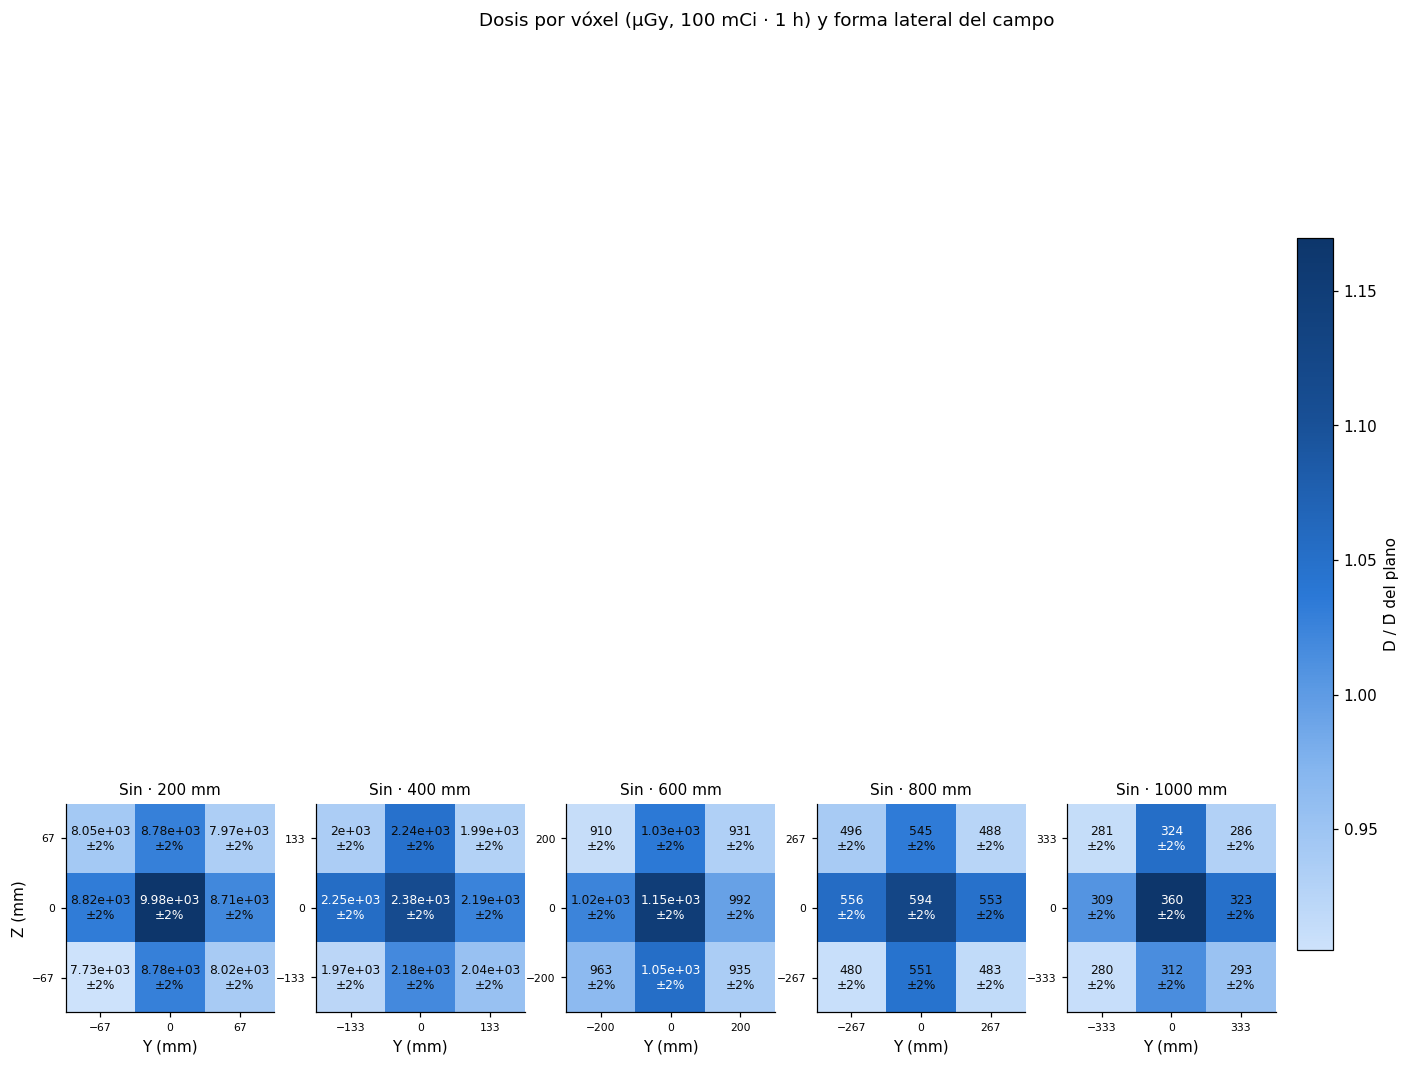

In [17]:
# Color = D / D̄ del plano (misma escala en todos los paneles → compara forma lateral).
# Texto  = dosis del vóxel (µGy) ± incertidumbre estadística.
todos = np.concatenate([(r["D"] / r["D"].mean()).ravel() for p in datos.values() for r in p.values()])
vmin, vmax = todos.min(), todos.max()

fig, axs = plt.subplots(len(datos), len(DISTANCIAS), figsize=(3.4 * len(DISTANCIAS), 3.5 * len(datos)),
                        squeeze=False)
for i, (cont, por_d) in enumerate(datos.items()):
    for j, d in enumerate(DISTANCIAS):
        ax = axs[i][j]
        if d not in por_d: ax.axis("off"); continue
        r = por_d[d]; D = r["D"]; n = D.shape[0]; h = r["lado"] / 2
        patron = D / D.mean()
        im = ax.imshow(patron, origin="lower", extent=[-h, h, -h, h], cmap=CMAP_AZUL,
                       vmin=vmin, vmax=vmax)
        paso = r["lado"] / n
        cen = (np.arange(n) + 0.5) * paso - h
        for a in range(n):          # a = índice Z (fila), b = índice Y (columna)
            for b in range(n):
                claro = (patron[a, b] - vmin) / (vmax - vmin) > 0.55
                ax.text(cen[b], cen[a], f"{D[a, b]*1e6:.3g}\n±{100*r['u'][a, b]:.0f}%",
                        ha="center", va="center", fontsize=8, color="white" if claro else TINTA)
        ax.set_title(f"{cont.split()[0]} · {d} mm", fontsize=10)
        ax.set_xticks(np.round(cen)); ax.set_yticks(np.round(cen)); ax.grid(False)
        ax.tick_params(labelsize=7)
        if i == len(datos) - 1: ax.set_xlabel("Y (mm)")
        if j == 0: ax.set_ylabel("Z (mm)")
cb = fig.colorbar(im, ax=axs, shrink=0.8, pad=0.015); cb.set_label("D / D̄ del plano")
fig.suptitle("Dosis por vóxel (µGy, 100 mCi · 1 h) y forma lateral del campo", y=1.0)
fig.savefig(FIG_DIR / "fig_mapas_calor.png", dpi=200, bbox_inches="tight"); plt.show()

### 3.4 Atenuación a través del blindaje
#### Perfil de dosis vs posición

Muestra cómo decae la dosis al atravesar cada capa del blindaje desde la fuente hasta `det_torso` a 15 cm de la superficie. En general se verá mucho ruido en el exterior del blindaje si se mantiene la emulación con primarios entorno a los cien millones.

## 3.3 Modelo teórico: Point-Kernel

El modelo analítico Point-Kernel estima la tasa de dosis equivalente ambiental H*(10) a una distancia $r$ del centro del contenedor como:

$$\dot{H}(r) = \Gamma_\delta \cdot \frac{A}{r^2} \cdot e^{-\sum_i \mu_i x_i}$$

donde:
- $\Gamma_\delta(\text{F-18}) = 0.135\ \mu\text{Sv·m}^2\text{·MBq}^{-1}\text{·h}^{-1}$
- $A = 100\ \text{mCi} = 3700\ \text{MBq}$
- $\mu_i, x_i$ — coeficiente de atenuación lineal y espesor de la capa $i$
- $r$ — distancia desde el centro del contenedor (m)

| Material  | $\mu$ (cm⁻¹) |
|-----------|-------------|
| Agua      | 0.0966      |
| Vidrio    | 0.112       |
| Aire      | 0.000112    |
| Plomo     | 1.781       |
| Acero     | 0.624       |
| Tungsteno | 2.402       |

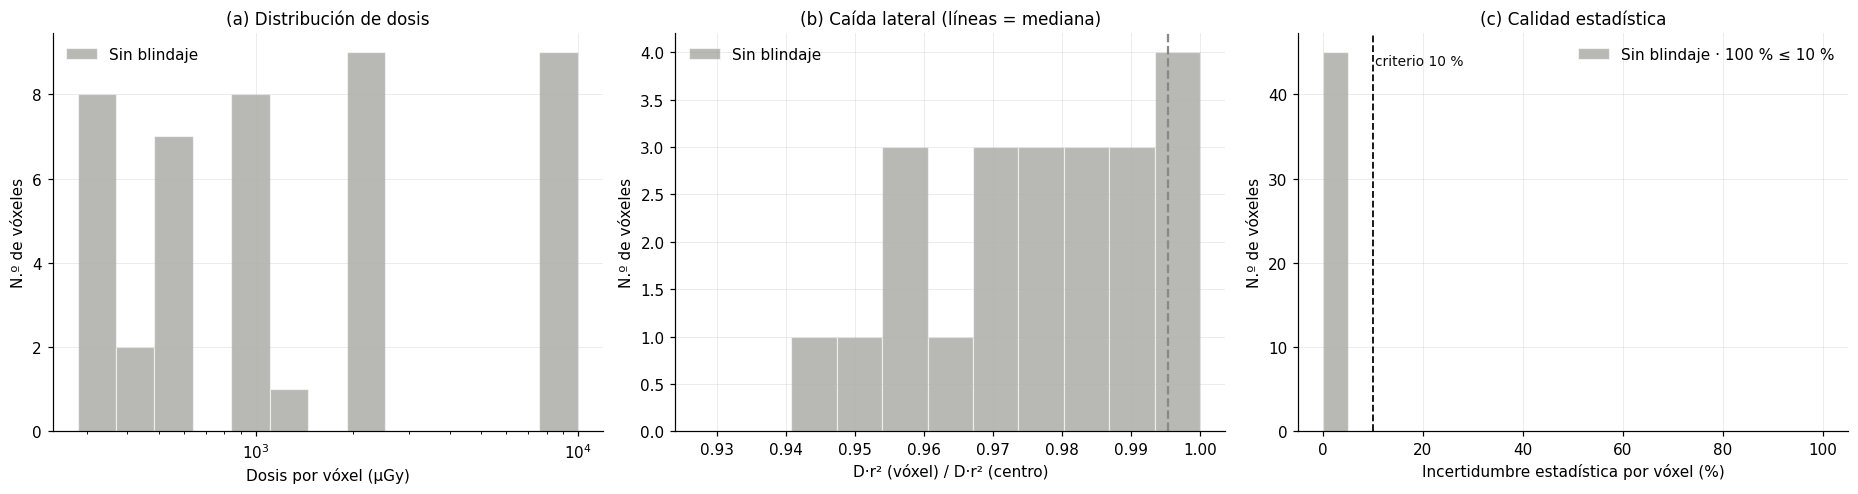

In [18]:
# Cada plano solo tiene 9 vóxeles, así que se agrupan los 5 planos de cada contenedor.
def vox_arrays(cont):
    dosis, patron, unc = [], [], []
    for d, r in sorted(datos[cont].items()):
        D = r["D"]; n = D.shape[0]; c = (np.arange(n) + 0.5) * r["lado"] / n - r["lado"] / 2
        Y, Z = np.meshgrid(c, c)                           # filas = Z, columnas = Y
        q = D * (d ** 2 + Y ** 2 + Z ** 2)                 # D·r²: quita la geometría 1/r²
        q = q / q[n // 2, n // 2]                          # respecto al vóxel central
        mask = np.ones_like(q, bool); mask[n // 2, n // 2] = False
        dosis += list(D.ravel() * 1e6); patron += list(q[mask]); unc += list(100 * r["u"].ravel())
    return np.array(dosis), np.array(patron), np.array(unc)

V = {cont: vox_arrays(cont) for cont in datos if datos[cont]}
fig, ax = plt.subplots(1, 3, figsize=(17, 4.6))

# (a) dosis por vóxel, bins logarítmicos comunes
todas = np.concatenate([v[0] for v in V.values()])
bins = np.logspace(np.log10(todas.min()), np.log10(todas.max()), 14)
for cont, (dosis, _, _) in V.items():
    ax[0].hist(dosis, bins=bins, color=COLORES[cont], alpha=0.6, edgecolor="white", lw=0.8, label=cont)
ax[0].set(xscale="log", xlabel="Dosis por vóxel (µGy)", ylabel="N.º de vóxeles",
          title="(a) Distribución de dosis"); ax[0].legend()

# (b) caída lateral: D·r² del vóxel / D·r² del centro (1 = sin caída)
bins_b = np.linspace(min(v[1].min() for v in V.values()) * 0.98, 1.0, 12)
for cont, (_, pat, _) in V.items():
    ax[1].hist(pat, bins=bins_b, color=COLORES[cont], alpha=0.6, edgecolor="white", lw=0.8, label=cont)
    ax[1].axvline(np.median(pat), color=COLORES[cont], lw=1.5, ls="--")
ax[1].set(xlabel="D·r² (vóxel) / D·r² (centro)", ylabel="N.º de vóxeles",
          title="(b) Caída lateral (líneas = mediana)"); ax[1].legend()

# (c) calidad estadística
tope = max(100, max(v[2].max() for v in V.values()))
bins_c = np.linspace(0, min(tope, 100), 21)
for cont, (_, _, unc) in V.items():
    ax[2].hist(np.clip(unc, 0, 100), bins=bins_c, color=COLORES[cont], alpha=0.6, edgecolor="white",
               lw=0.8, label=f"{cont} · {np.mean(unc <= 100*UMBRAL_INCERT)*100:.0f} % ≤ 10 %")
ax[2].axvline(100 * UMBRAL_INCERT, color=TINTA, lw=1.2, ls="--")
ax[2].text(100 * UMBRAL_INCERT + 0.5, ax[2].get_ylim()[1] * 0.92, "criterio 10 %", fontsize=9, color=TINTA)
ax[2].set(xlabel="Incertidumbre estadística por vóxel (%)", ylabel="N.º de vóxeles",
          title="(c) Calidad estadística"); ax[2].legend()
fig.tight_layout(); fig.savefig(FIG_DIR / "fig_histogramas.png", dpi=200, bbox_inches="tight"); plt.show()

## 3.4 Comparación GATE vs. modelo teórico

Se superponen los resultados Monte Carlo (puntos con barras de incertidumbre) y las curvas Point-Kernel (líneas discontinuas). Se incluyen los límites ICRP de referencia:

- **Trabajadores expuestos**: 20 mSv/año → **2.28 µSv/h**
- **Público general**: 1 mSv/año → **0.114 µSv/h**

## 4. Conclusiones

### 4.1 Atenuación: tungsteno vs. plomo

El modelo Point-Kernel predice un factor de atenuación de **~3.4×** a favor del tungsteno, consecuencia de la diferencia en coeficientes de atenuación (μ_W = 2.402 cm⁻¹ vs. μ_Pb = 1.781 cm⁻¹) y los espesores de cada contenedor.

### 4.2 Cumplimiento de límites ICRP

- **Trabajadores (20 mSv/año → 2.28 µSv/h):** ambos contenedores se sitúan por debajo del límite a partir de ~20–30 cm del centro.
- **Público general (1 mSv/año → 0.114 µSv/h):** el tungsteno alcanza este umbral a menor distancia que el plomo.



In [9]:
import json, numpy as np
from pathlib import Path

carpeta = Path("resultados/sin_blindaje/test_gamma_200mm_t5mm")
TEORIA_DOSIS = 4.64e-16      # Gy/fotón, media del plano
TEORIA_EDEP  = 5.97e-4       # MeV/fotón, total del plano

def leer_mhd(ruta):
    h = {}
    for l in Path(ruta).read_text().splitlines():
        if "=" in l:
            k, v = l.split("=", 1); h[k.strip()] = v.strip()
    dims = [int(x) for x in h["DimSize"].split()]
    tipo = {"MET_FLOAT": "<f4", "MET_DOUBLE": "<f8"}[h["ElementType"]]
    raw = carpeta / h["ElementDataFile"]
    return np.fromfile(raw, dtype=tipo).reshape(dims[::-1])

n = json.loads((carpeta / "metadata_simulacion.json").read_text())["n_primarios_simulados"]
print("Archivos:", sorted(p.name for p in carpeta.glob("*.mhd")))

dosis = leer_mhd(next(carpeta.glob("*_dose.mhd")))
unc   = leer_mhd(next(carpeta.glob("*_dose_uncertainty.mhd")))
edep  = leer_mhd(next(carpeta.glob("*_edep.mhd")))

d_fot = dosis / n              # Gy por fotón emitido (el archivo es el total de la corrida)
e_fot = edep.sum() / n         # MeV por fotón emitido (si edep viene en MeV)

print(f"\nFotones simulados      : {n:,}")
print(f"Dosis media / fotón    : {d_fot.mean():.3e} Gy   (teoría {TEORIA_DOSIS:.2e})")
print(f"  cociente MC/teoría   : {d_fot.mean()/TEORIA_DOSIS:.3f}")
print(f"Edep total / fotón     : {e_fot:.3e} MeV (teoría {TEORIA_EDEP:.2e})")
print(f"  cociente MC/teoría   : {e_fot/TEORIA_EDEP:.3f}")
print(f"Incertidumbre relativa por vóxel: {np.round(unc.ravel()*100,2)} %")
print("\nDosis/fotón por vóxel (Gy):\n", d_fot.squeeze())

Archivos: ['dose_det_200mm_dose.mhd', 'dose_det_200mm_dose_uncertainty.mhd', 'dose_det_200mm_edep.mhd']

Fotones simulados      : 5,000,000
Dosis media / fotón    : 1.141e-16 Gy   (teoría 4.64e-16)
  cociente MC/teoría   : 0.246
Edep total / fotón     : 1.467e-04 MeV (teoría 5.97e-04)
  cociente MC/teoría   : 0.246
Incertidumbre relativa por vóxel: [5.66 5.23 5.55 5.07 4.86 5.2  5.8  5.18 5.64] %

Dosis/fotón por vóxel (Gy):
 [[1.01124366e-16 1.14147765e-16 1.03954235e-16]
 [1.21084883e-16 1.39338226e-16 1.23657543e-16]
 [1.00814925e-16 1.19870118e-16 1.02818124e-16]]


In [10]:
f = Path("resultados/sin_blindaje/test_gamma_200mm_t5mm")
D = leer_mhd(f / "dose_det_200mm_dose.mhd")[:, :, 0]
E = leer_mhd(f / "dose_det_200mm_edep.mhd")
n = json.loads((f / "metadata_simulacion.json").read_text())["n_primarios_simulados"]
teo = 4.64e-16
print(f"dosis media por fotón: {D.mean()/n:.3e} Gy | esperado {teo:.3e} | cociente {D.mean()/n/teo:.3f}")
print(f"edep por fotón: {E.sum()/n:.3e} MeV | esperado 5.97e-4")
print("incertidumbre máx. vóxel:", leer_mhd(f / "dose_det_200mm_dose_uncertainty.mhd").max())

dosis media por fotón: 1.141e-16 Gy | esperado 4.640e-16 | cociente 0.246
edep por fotón: 1.467e-04 MeV | esperado 5.97e-4
incertidumbre máx. vóxel: 0.058031418643026765


In [28]:
!ls resultados/sin_blindaje
!find . -name "*test_gamma*" -maxdepth 4

plano_200mm_t5mm
find: atención: ha especificado la opción global -maxdepth después de un argumento -name, pero las opciones globales no son posicionales, p.e., -maxdepth afecta las pruebas especificadas antes de ella así como las especificadas después de ella. Por favor especifique las opciones globales antes que cualquier otro argumento.
./vial_test_gamma.py


In [5]:
import json, numpy as np
from pathlib import Path

def leer(carpeta, ruta):
    h = {}
    for l in Path(ruta).read_text().splitlines():
        if "=" in l:
            k, v = l.split("=", 1); h[k.strip()] = v.strip()
    dims = [int(x) for x in h["DimSize"].split()]
    tipo = {"MET_FLOAT": "<f4", "MET_DOUBLE": "<f8"}[h["ElementType"]]
    return np.fromfile(carpeta / h["ElementDataFile"], dtype=tipo).reshape(dims[::-1])

print(f"{'caso':38s} {'Edep/fotón MeV':>15s} {'teoría':>10s} {'MC/teoría':>10s} {'unc %':>6s}")
for c in sorted(Path("resultados/sin_blindaje").glob("test_esfera_*")):
    meta = json.loads((c / "metadata_simulacion.json").read_text())
    e = leer(c, next(c.glob("*_edep.mhd"))).sum() / meta["n_primarios_simulados"]
    u = leer(c, next(c.glob("*_dose_uncertainty.mhd"))).ravel()[0] * 100
    t = meta["edep_teorica_MeV_por_foton"]
    print(f"{c.name:38s} {e:15.3e} {t:10.2e} {e/t:10.3f} {u:6.2f}")

caso                                    Edep/fotón MeV     teoría  MC/teoría  unc %
test_esfera_R200mm_t20mm_pre                 3.650e-02   3.47e-02      1.051   0.18
test_esfera_R200mm_t5mm_pre                  9.128e-03   8.68e-03      1.051   0.37
test_esfera_R200mm_t5mm_random               9.101e-03   8.68e-03      1.048   0.37


In [6]:
import json, numpy as np
from pathlib import Path

def leer(carpeta, ruta):
    h = {}
    for l in Path(ruta).read_text().splitlines():
        if "=" in l:
            k, v = l.split("=", 1); h[k.strip()] = v.strip()
    dims = [int(x) for x in h["DimSize"].split()]
    tipo = {"MET_FLOAT": "<f4", "MET_DOUBLE": "<f8"}[h["ElementType"]]
    return np.fromfile(carpeta / h["ElementDataFile"], dtype=tipo).reshape(dims[::-1])

print(f"{'caso':36s} {'Edep/fotón':>11s} {'teoría':>9s} {'MC/teoría':>10s} {'unc % (media)':>14s}")
for c in sorted(Path("resultados/sin_blindaje").glob("test_gamma_*_v*")):
    meta = json.loads((c / "metadata_simulacion.json").read_text())
    n, t = meta["n_primarios_simulados"], meta["detector"]["espesor_mm"]
    e = leer(c, next(c.glob("*_edep.mhd"))).sum() / n
    u = leer(c, next(c.glob("*_dose_uncertainty.mhd"))).mean() * 100
    teo = 5.97e-4 * t / 5.0
    print(f"{c.name:36s} {e:11.3e} {teo:9.2e} {e/teo:10.3f} {u:14.2f}")

caso                                  Edep/fotón    teoría  MC/teoría  unc % (media)
test_gamma_200mm_t5mm_v1               1.338e-04  5.97e-04      0.224           1.85
test_gamma_200mm_t5mm_v3               1.388e-04  5.97e-04      0.233           5.50


In [7]:
import json, numpy as np
from pathlib import Path

c = Path("resultados/sin_blindaje/test_esfera_R200mm_t5mm_pre_v3")
meta = json.loads((c / "metadata_simulacion.json").read_text())
n = meta["n_primarios_simulados"]

def leer(ruta):
    h = {}
    for l in Path(ruta).read_text().splitlines():
        if "=" in l:
            k, v = l.split("=", 1); h[k.strip()] = v.strip()
    dims = [int(x) for x in h["DimSize"].split()]
    tipo = {"MET_FLOAT": "<f4", "MET_DOUBLE": "<f8"}[h["ElementType"]]
    return np.fromfile(c / h["ElementDataFile"], dtype=tipo).reshape(dims[::-1])  # índices [z, y, x]

E = leer(next(c.glob("*_edep.mhd"))) / n
print(f"Edep total/fotón: {E.sum():.3e} MeV   (teoría {meta['edep_teorica_MeV_por_foton']:.3e})\n")

caras = {"-X": E[1,1,0], "+X": E[1,1,2], "-Y": E[1,0,1], "+Y": E[1,2,1], "-Z": E[0,1,1], "+Z": E[2,1,1]}
media = np.mean(list(caras.values()))
for k, v in caras.items():
    print(f"cara {k}: {v:.3e} MeV/fotón   relativo a la media de las 6: {v/media:.3f}")

Edep total/fotón: 9.112e-03 MeV   (teoría 8.684e-03)

cara -X: 3.551e-04 MeV/fotón   relativo a la media de las 6: 1.002
cara +X: 3.562e-04 MeV/fotón   relativo a la media de las 6: 1.005
cara -Y: 3.571e-04 MeV/fotón   relativo a la media de las 6: 1.008
cara +Y: 3.494e-04 MeV/fotón   relativo a la media de las 6: 0.986
cara -Z: 3.589e-04 MeV/fotón   relativo a la media de las 6: 1.013
cara +Z: 3.494e-04 MeV/fotón   relativo a la media de las 6: 0.986


In [8]:
import json, math, numpy as np
from pathlib import Path

def leer(c, ruta):
    h = {}
    for l in Path(ruta).read_text().splitlines():
        if "=" in l:
            k, v = l.split("=", 1); h[k.strip()] = v.strip()
    dims = [int(x) for x in h["DimSize"].split()]
    tipo = {"MET_FLOAT": "<f4", "MET_DOUBLE": "<f8"}[h["ElementType"]]
    return np.fromfile(c / h["ElementDataFile"], dtype=tipo).reshape(dims[::-1])

print(f"{'caso':44s} {'Edep/fotón':>11s} {'teoría':>9s} {'MC/teoría':>10s}")
for c in sorted(Path("resultados/sin_blindaje").glob("test_gamma_*_k*")):
    meta = json.loads((c / "metadata_simulacion.json").read_text())
    d = meta["detector"]
    b, D, t = d["lado_mm"] / 2, d["distancia_mm"], d["espesor_mm"]
    omega = 4 * math.asin(b**2 / (b**2 + D**2))
    teo = 8.684e-3 * omega / (4 * math.pi) * t / 5.0
    e = leer(c, next(c.glob("*_edep.mhd"))).sum() / meta["n_primarios_simulados"]
    print(f"{c.name:44s} {e:11.3e} {teo:9.2e} {e/teo:10.3f}")

caso                                          Edep/fotón    teoría  MC/teoría
test_gamma_200mm_t5mm_v1_+x_k1                 5.199e-04  5.57e-04      0.934
test_gamma_200mm_t5mm_v1_+z_k1                 5.255e-04  5.57e-04      0.944
test_gamma_200mm_t5mm_v1_-x_k0.5               4.159e-05  1.63e-04      0.256
test_gamma_200mm_t5mm_v1_-x_k2                 4.192e-04  1.45e-03      0.290
test_gamma_200mm_t5mm_v1_-z_k1                 1.398e-04  5.57e-04      0.251


In [19]:
import json, numpy as np
from pathlib import Path

def leer(c, ruta):
    h = {}
    for l in Path(ruta).read_text().splitlines():
        if "=" in l:
            k, v = l.split("=", 1); h[k.strip()] = v.strip()
    dims = [int(x) for x in h["DimSize"].split()]
    tipo = {"MET_FLOAT": "<f4", "MET_DOUBLE": "<f8"}[h["ElementType"]]
    return np.fromfile(c / h["ElementDataFile"], dtype=tipo).reshape(dims[::-1])

def media_por_d2(base):
    out = {}
    for d in (200, 400, 600, 800, 1000):
        c = Path(f"resultados/{base}/plano_{d}mm_t5mm")
        if not c.exists(): continue
        n = json.loads((c / "metadata_simulacion.json").read_text())["n_primarios_simulados"]
        out[d] = leer(c, next(c.glob("*_dose.mhd"))).mean() / n * d**2
    return out

a, b = media_por_d2("sin_blindaje"), media_por_d2("sin_blindaje_ens")
print(f"{'d':>5s} {'normal':>8s} {'ens':>8s}   (media·d², relativa a 200 mm de cada serie)")
for d in sorted(set(a) | set(b)):
    ra = a[d]/a[200] if d in a else float('nan')
    rb = b[d]/b[200] if d in b else float('nan')
    print(f"{d:5d} {ra:8.3f} {rb:8.3f}")

    d   normal      ens   (media·d², relativa a 200 mm de cada serie)
  200    1.000    1.000
  400    1.002    1.024
  600    1.053    1.069
  800    0.989    1.021
 1000    0.900    0.933


In [20]:
import json, re, numpy as np
from pathlib import Path

def leer(c, ruta):
    h = {}
    for l in Path(ruta).read_text().splitlines():
        if "=" in l:
            k, v = l.split("=", 1); h[k.strip()] = v.strip()
    dims = [int(x) for x in h["DimSize"].split()]
    tipo = {"MET_FLOAT": "<f4", "MET_DOUBLE": "<f8"}[h["ElementType"]]
    return np.fromfile(c / h["ElementDataFile"], dtype=tipo).reshape(dims[::-1])

filas = []
for c in Path("resultados/sin_blindaje").glob("test_esfera_R*_t5mm_pre"):
    R = int(re.search(r"_R(\d+)mm", c.name).group(1))
    meta = json.loads((c / "metadata_simulacion.json").read_text())
    e = leer(c, next(c.glob("*_edep.mhd"))).sum() / meta["n_primarios_simulados"]
    filas.append((R, e))
filas.sort()
ref = filas[0][1]
print(f"{'R (mm)':>7s} {'Edep/fotón (MeV)':>17s} {'relativa a R=200':>17s}")
for R, e in filas:
    print(f"{R:7d} {e:17.4e} {e/ref:17.3f}")

 R (mm)  Edep/fotón (MeV)  relativa a R=200
    200        9.1285e-03             1.000
    400        9.2564e-03             1.014
    600        9.3314e-03             1.022
    800        9.2985e-03             1.019
   1000        9.2734e-03             1.016


In [21]:
import json, re, math, numpy as np
from pathlib import Path

def leer(c, ruta):
    h = {}
    for l in Path(ruta).read_text().splitlines():
        if "=" in l:
            k, v = l.split("=", 1); h[k.strip()] = v.strip()
    dims = [int(x) for x in h["DimSize"].split()]
    tipo = {"MET_FLOAT": "<f4", "MET_DOUBLE": "<f8"}[h["ElementType"]]
    return np.fromfile(c / h["ElementDataFile"], dtype=tipo).reshape(dims[::-1]).ravel()

LAM = math.log(2) / (109.77 * 60); A0 = 100 * 3.7e7; T = 3600
N_DEC = A0 / LAM * (1 - math.exp(-LAM * T))          # decaimientos en 1 h
MEV_J = 1.602176634e-13

filas = []
for c in sorted(Path("resultados/sin_blindaje").glob("esfera_*mm*")):
    meta = json.loads((c / "metadata_simulacion.json").read_text())
    d = meta["detector"]; n = meta["n_primarios_simulados"]
    edep = leer(c, next(c.glob("*_edep.mhd")))                    # MeV por rebanada (total de la corrida)
    unc  = leer(c, next(c.glob("*_dose_uncertainty.mhd")))
    masa = np.array(d["masa_kg"])
    dosis_uGy = edep * MEV_J / masa * N_DEC / n * 1e6             # µGy en 1 h
    k = len(dosis_uGy) // 2                                      # rebanada ecuatorial
    media = edep.sum() * MEV_J / masa.sum() * N_DEC / n * 1e6
    filas.append((c.name, d["distancia_mm"], dosis_uGy[k], unc[k]*100, media))

ref = filas[0][4] * filas[0][1]**2
print(f"{'caso':26s} {'ecuador µGy':>12s} {'unc %':>6s} {'media µGy':>10s} {'media·R² rel.':>14s} {'ecuador/media':>14s}")
for nombre, R, eq, u, med in filas:
    print(f"{nombre:26s} {eq:12.2f} {u:6.2f} {med:10.2f} {med*R**2/ref:14.3f} {eq/med:14.3f}")

caso                        ecuador µGy  unc %  media µGy  media·R² rel.  ecuador/media
esfera_1000mm                    472.89   0.56     468.23          1.000          1.010
esfera_200mm                   11430.21   0.56   11358.99          0.970          1.006
esfera_200mm_zc-22.35          11392.66   0.56   11396.42          0.974          1.000
esfera_400mm                    2940.26   0.56    2909.66          0.994          1.011
esfera_600mm                    1310.48   0.56    1303.45          1.002          1.005
esfera_800mm                     732.44   0.56     730.82          0.999          1.002


In [23]:
import json, math, numpy as np
from pathlib import Path

def leer(c, ruta):
    h = {}
    for l in Path(ruta).read_text().splitlines():
        if "=" in l:
            k, v = l.split("=", 1); h[k.strip()] = v.strip()
    dims = [int(x) for x in h["DimSize"].split()]
    tipo = {"MET_FLOAT": "<f4", "MET_DOUBLE": "<f8"}[h["ElementType"]]
    return np.fromfile(c / h["ElementDataFile"], dtype=tipo).reshape(dims[::-1]).ravel()

LAM = math.log(2) / (109.77 * 60); A0 = 100 * 3.7e7; T1H = 3600
N_DEC = A0 / LAM * (1 - math.exp(-LAM * T1H))
MEV_J = 1.602176634e-13

def cargar(carpeta):
    c = Path(carpeta)
    meta = json.loads((c / "metadata_simulacion.json").read_text())
    d, n = meta["detector"], meta["n_primarios_simulados"]
    edep = leer(c, next(c.glob("*_edep.mhd")))
    unc  = leer(c, next(c.glob("*_dose_uncertainty.mhd"))) * 100
    dosis = edep * MEV_J / np.array(d["masa_kg"]) * N_DEC / n * 1e6      # µGy en 1 h
    return d, n, dosis, unc

d, n, pb, upb = cargar("resultados/plomo/esfera_200mm")
_, _, sb, usb = cargar("resultados/sin_blindaje/esfera_200mm")

print(f"Plomo 200 mm — {n:,} primarios\n")
print(f"{'rebanada':>8s} {'z (mm)':>8s} {'elev.(°)':>9s} {'Pb (µGy)':>10s} {'unc %':>6s} {'sin bl. (µGy)':>14s} {'T = Pb/sin':>11s}")
for i, (zc, th) in enumerate(zip(d["z_centros_mm"], d["polar_centro_deg"])):
    marca = "  ← ecuador" if i == len(pb)//2 else ""
    print(f"{i:8d} {zc:8.1f} {90-th:9.1f} {pb[i]:10.3f} {upb[i]:6.2f} {sb[i]:14.1f} {pb[i]/sb[i]:11.2e}{marca}")

Plomo 200 mm — 20,000,000 primarios

rebanada   z (mm)  elev.(°)   Pb (µGy)  unc %  sin bl. (µGy)  T = Pb/sin
       0   -186.4     -68.7    416.707   1.49        10456.9    3.98e-02
       1   -149.1     -48.2    181.298   2.15        11365.6    1.60e-02
       2   -111.8     -34.0     54.754   3.79        11334.8    4.83e-03
       3    -74.5     -21.9     55.258   3.88        11373.9    4.86e-03
       4    -37.3     -10.7     58.547   3.76        11465.4    5.11e-03
       5      0.0       0.0     67.857   3.53        11430.2    5.94e-03  ← ecuador
       6     37.3      10.7     65.100   3.69        11337.4    5.74e-03
       7     74.5      21.9     53.061   4.00        11387.9    4.66e-03
       8    111.8      34.0     31.377   5.17        11584.2    2.71e-03
       9    149.1      48.2     16.142   6.64        11593.3    1.39e-03
      10    186.4      68.7    142.807   2.57        11573.3    1.23e-02
